# Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

## Part 0: Set Up

#### 0.1 Import Libraries

In [1]:
# Importing the Seaborn library for advanced data visualization (as sns)
import seaborn as sns

# Importing the Matplotlib library for basic plotting functionalities (as plt)
import matplotlib.pyplot as plt

# Importing the Pandas library for data manipulation and analysis (as pd)
import pandas as pd

# Importing the NumPy library for numerical operations (as np)
import numpy as np

# importing Chi-Square-test
from scipy.stats import chi2_contingency

# importing Cramér's V
from scipy.stats.contingency import association



#### 0.2 Set Plot Design

In [55]:
# Matplotlib inline to visualize Matplotlib graphs
%matplotlib inline

# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'

# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set(rc={"figure.figsize": (30., 10.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
sns.set_style("whitegrid")
#### 0.3 Load & Understand Data

In [3]:
%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.
Path to dataset files: C:\Users\black\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [4]:
df = pd.read_csv(r"C:\Users\black\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3\amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
# splitting dataset in numerical and categorial subsets 

num = df.select_dtypes(include="number") 
cat = df.select_dtypes(exclude="number")

## Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

#### 1.1 **Crosstab Analysis**:
- Create a crosstab between the product `category` and the `isBestSeller` status.
    
- Are there categories where being a best-seller is more prevalent? 
 	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [73]:
# crosstab category - isBestSeller

cross_cat_best = pd.crosstab(cat["category"], cat["isBestSeller"])
cross_cat_best.T

category,3D Printers,3D Printing & Scanning,Abrasive & Finishing Products,Action Cameras,Adapters,Agricultural Equipment & Supplies,Alexa Built-In Devices,Art & Craft Supplies,Arts & Crafts,Baby,...,Uninterruptible Power Supply Units & Accessories,Vacuums & Floorcare,Vases,"Water Coolers, Filters & Cartridges",Wearable Technology,Wind Instruments,Window Treatments,Women,Women's Sports & Outdoor Shoes,eBook Readers & Accessories
isBestSeller,,,,,,,,,,,,,,,,,,,,,
False,247,4065,245,1696,251,8421,106,253,9319,14709,...,3652,6919,250,186,8876,243,234,17559,1939,246
True,1,2,5,1,3,109,1,5,230,341,...,1,26,0,1,30,7,5,213,20,0


In [74]:
cross_cat_best_norm = pd.crosstab(cat["category"], cat["isBestSeller"], normalize="index")
cross_cat_best_sorted = cross_cat_best_norm.sort_values(by=True, ascending=False)
cross_cat_best_sorted


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


#### 1.2 **Statistical Tests**:
- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [81]:
# Chi-square test for 'category' and 'isBestSeller'
_, chi2_pvalue, _, _  = chi2_contingency(cross_cat_best) # _ because this function has 4 returns; so if we do not want to add the variables, we can substitute by "_"
display(float(chi2_pvalue))
float(chi2_pvalue) < 0.05

0.0

True

In [80]:
# Computing the association between variables in 'cross_cat_best' using the "cramer" method
association(cross_cat_best, method='cramer')

0.1222829439760564

Our 0-hypothesis that the best-seller distribution is independent. The Chi-Square test has a p-value of 0.0 which gives us a high confidence level to reject the 0-hypothesis. 
The Cramér's V interpretations shows that values between 0.10 – 0.20 are considered a weak strength of association and with 0.122 as our outcome, we can see it being on the even weaker side.


#### 1.3 **Visualizations**:
- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

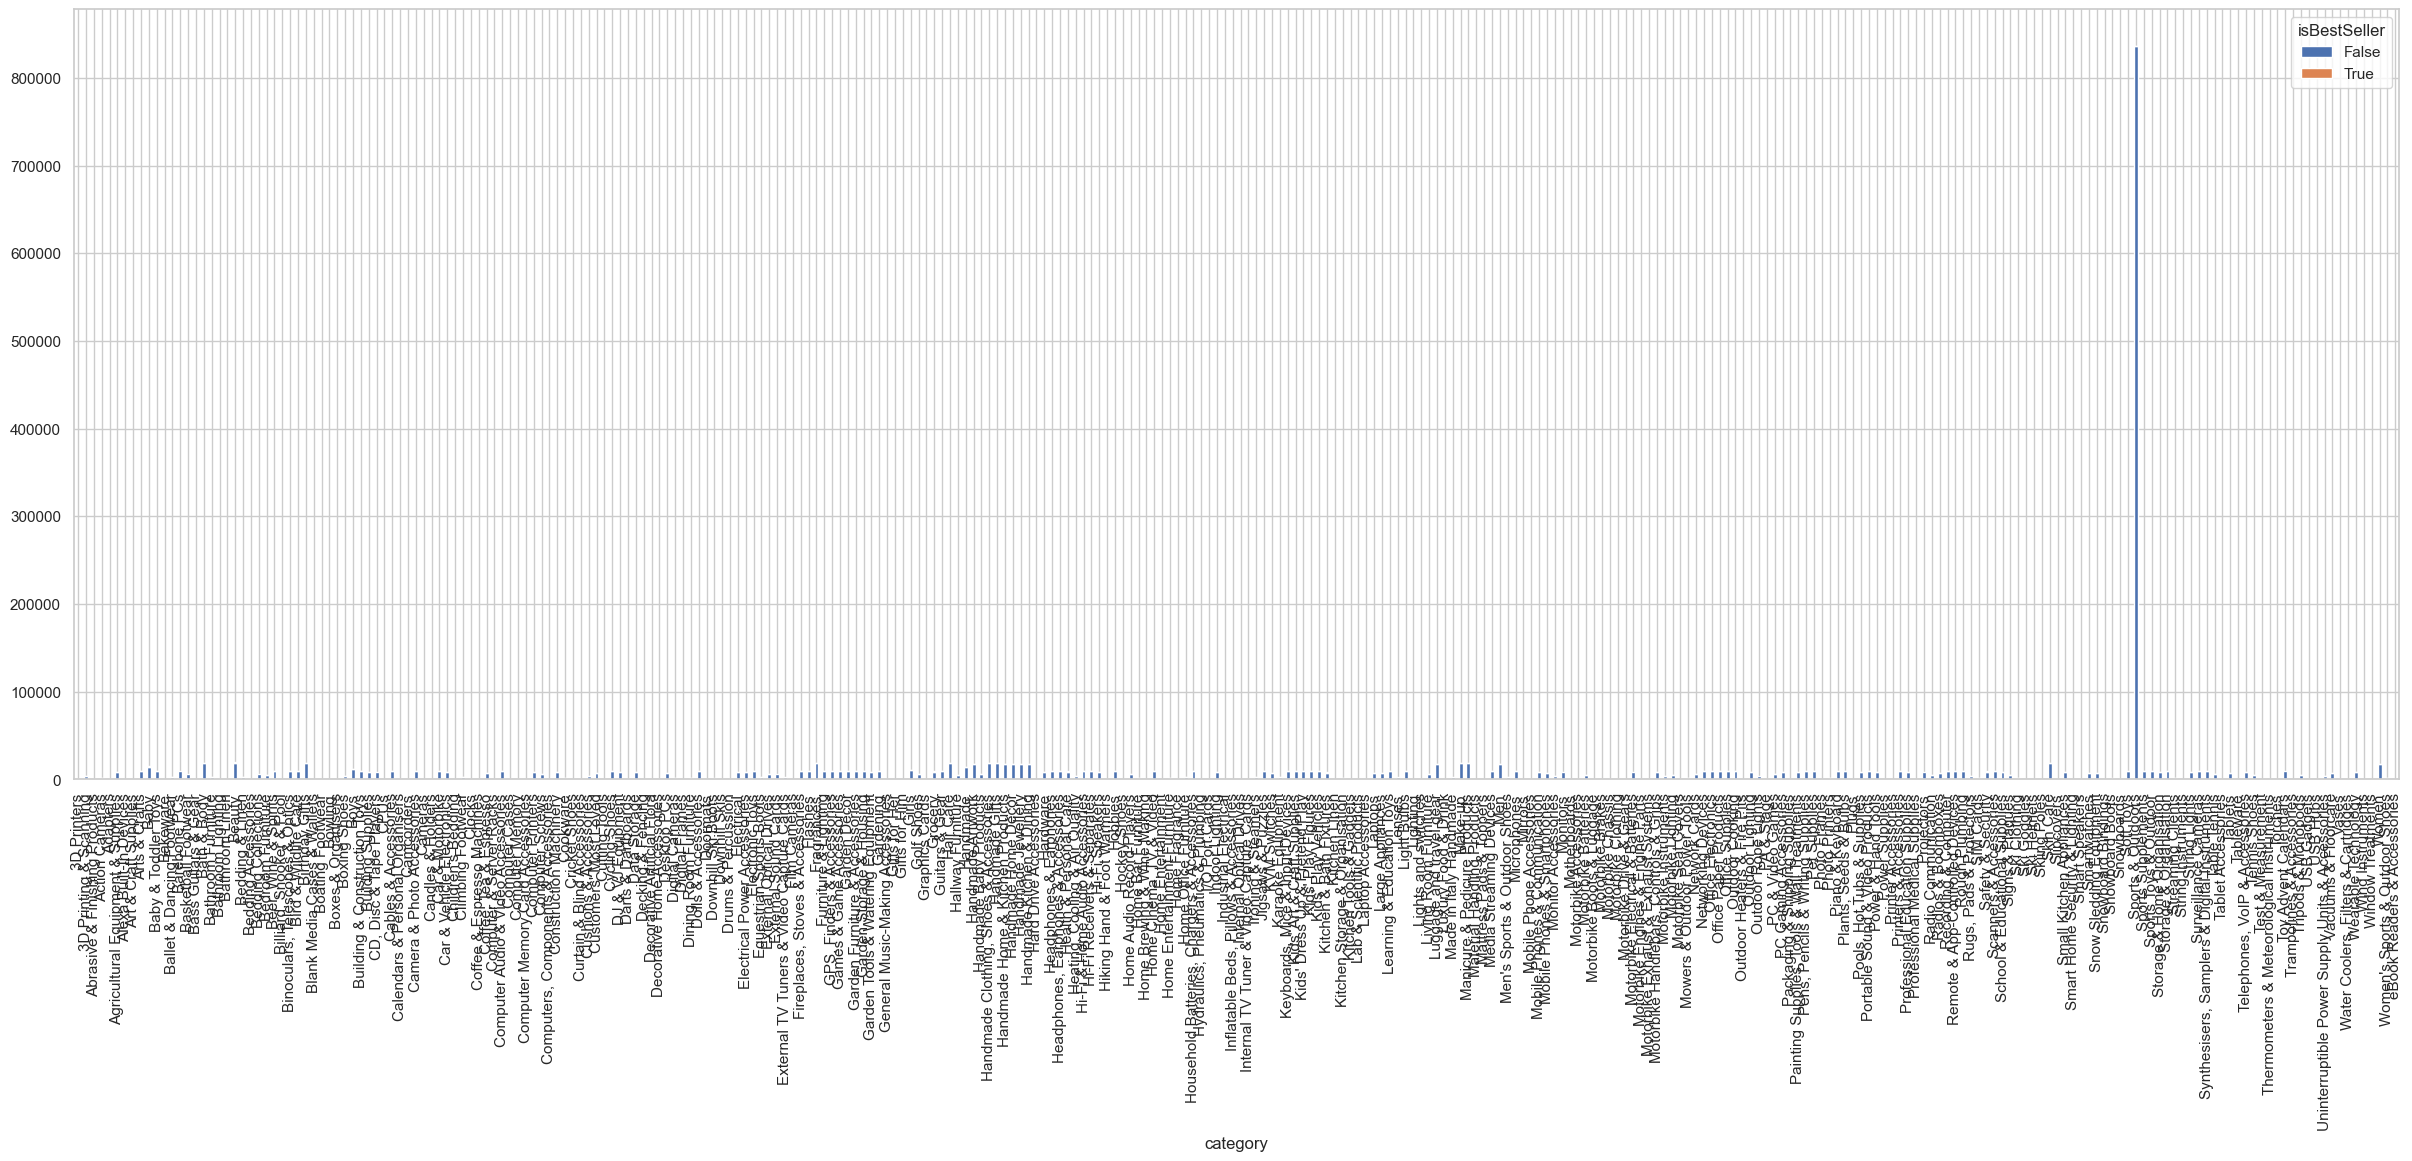

In [56]:
# Plotting a stacked bar chart for the 'crosstab_result' data

cross_cat_best.plot(kind='bar', stacked=True)
plt.show()

We can see the "False" as being a best selling item within each product category is the most dominant case across all categories. A close up of the top 10 categories and lowest 10 categories will make it clearer.

In [ ]:
# sorting based on top & tail

cat_sort_top = cross_cat_best.sort_values(ascending=False, by=False).head(10)
cat_sort_tail = cross_cat_best_sorted.sort_values(ascending=False, by=False).tail(10)

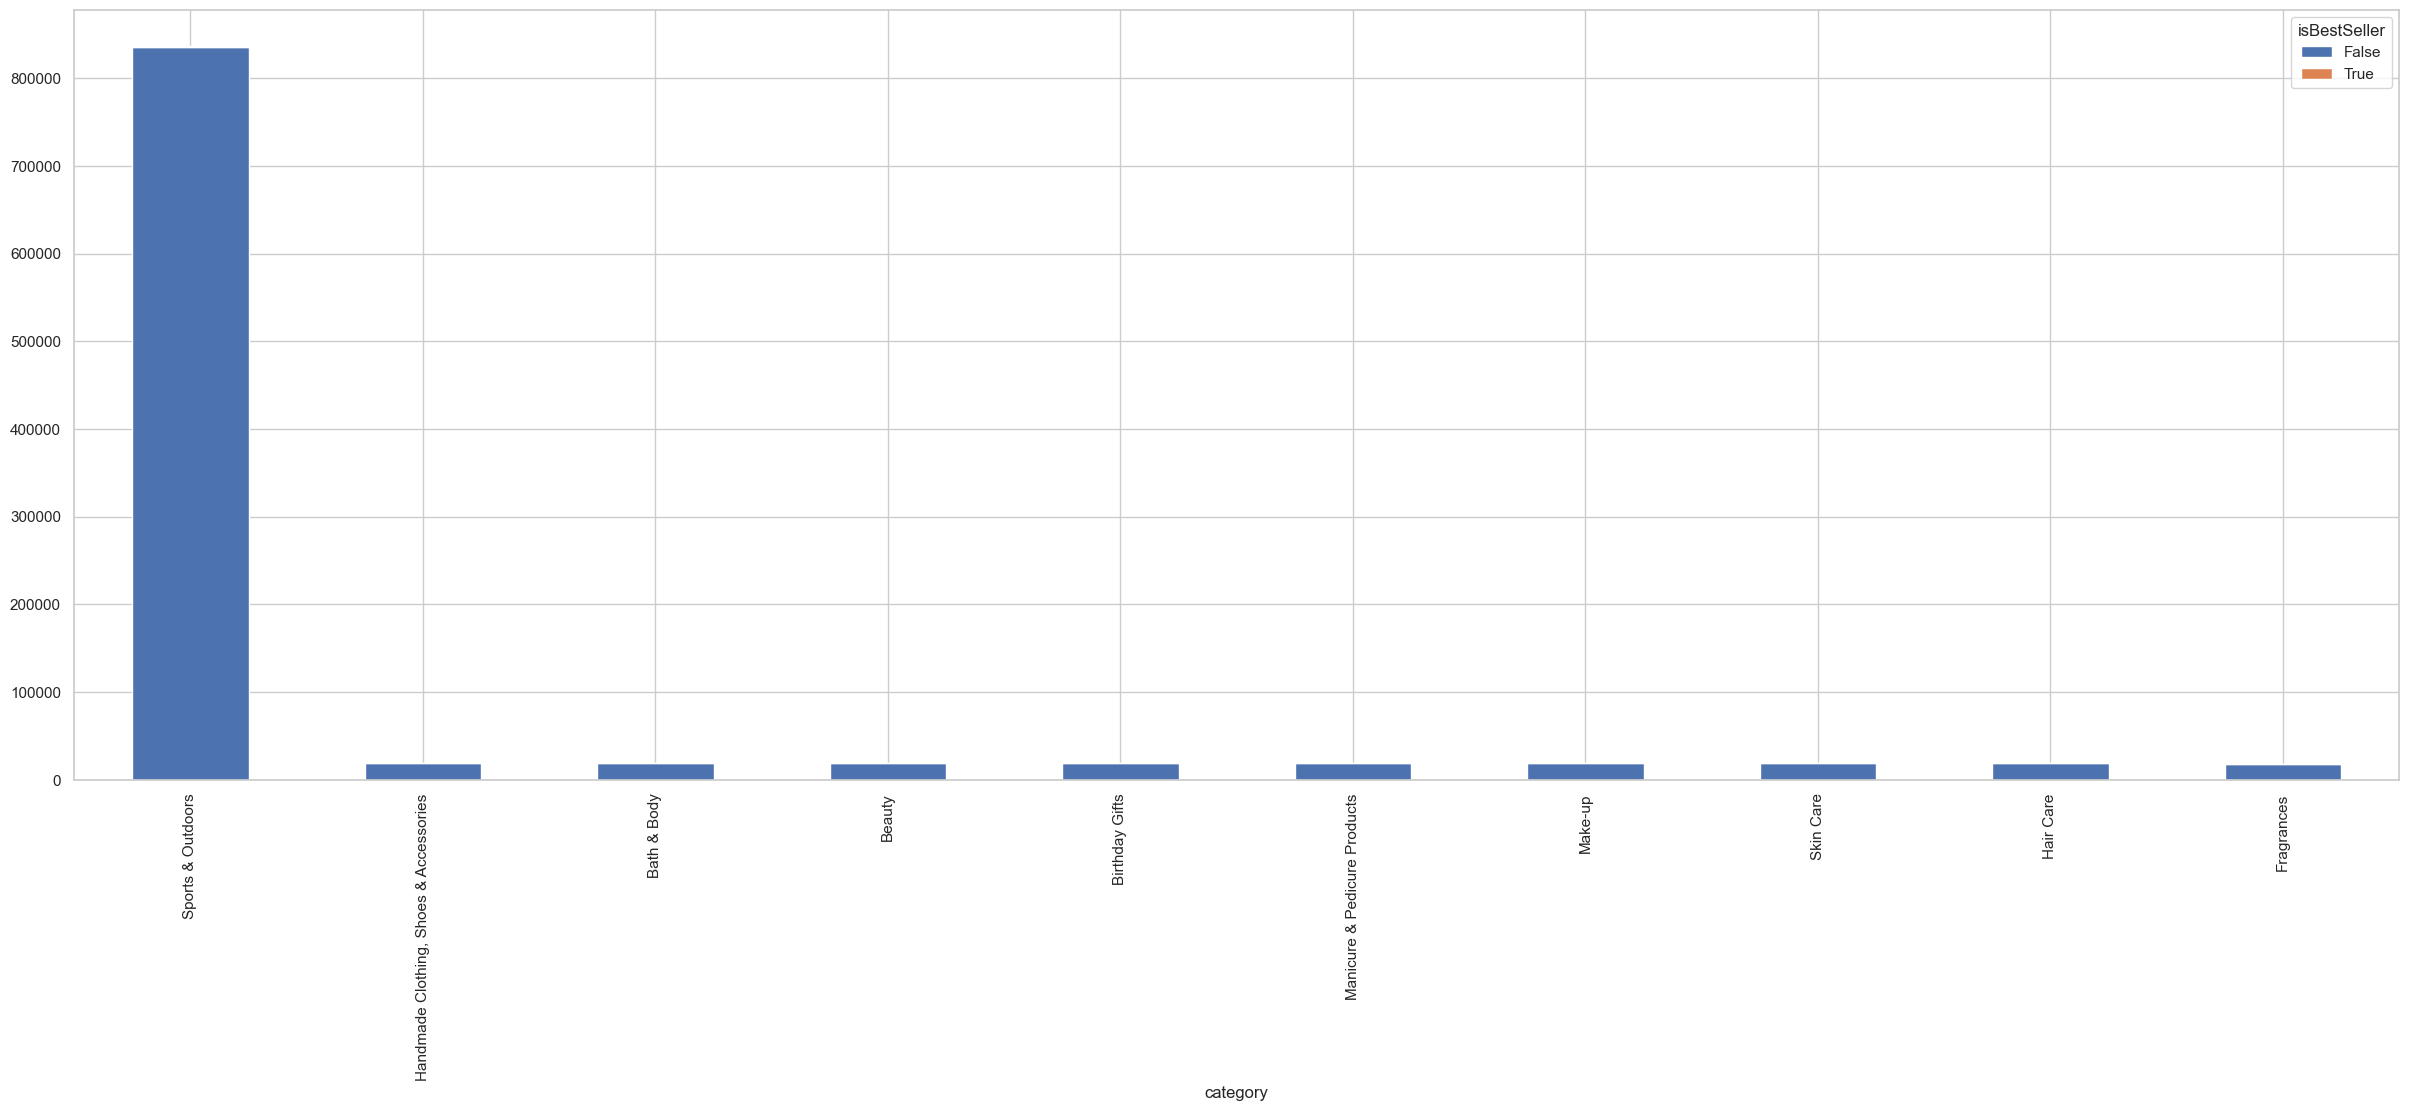

In [ ]:
# plot top 10 categories 
cat_sort_top.plot(kind='bar', stacked=True)
plt.show()

The close up of the top 10 categories and the best selling products shows that there is an outstanding abundance of "Falses" regarding the best selling items, so much, that the "Trues" are not on display.

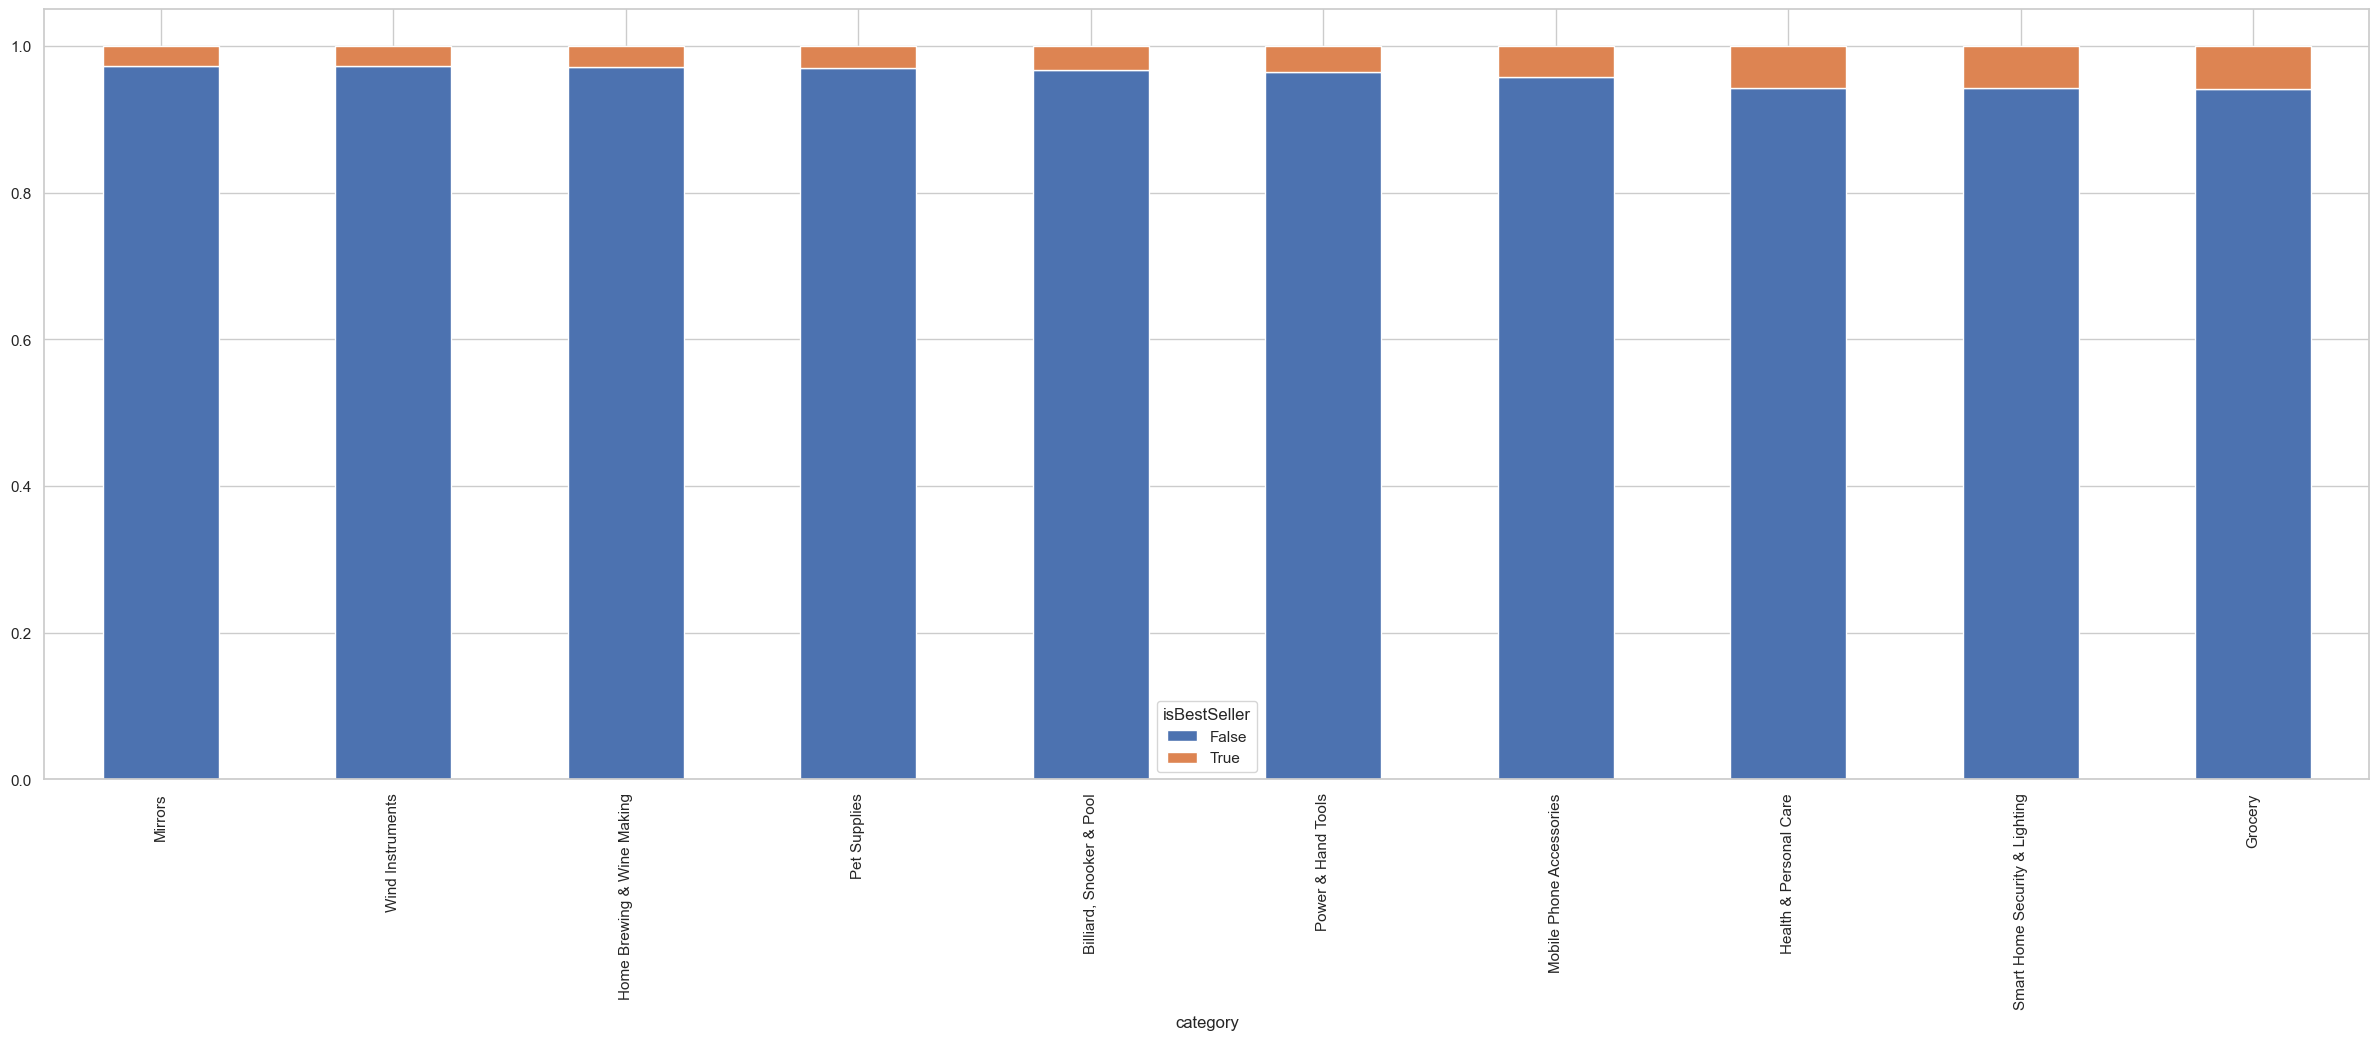

In [ ]:
# plot least 10 categories
cat_sort_tail.plot(kind='bar', stacked=True)
plt.show()

A close up of the categories with the least amount of items is also showing some best selling categories. 

All over we can interprete, that only very few items make it to the "Best Selling List".

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.


### 2.0 **Preliminary Step: Remove outliers in product prices.**

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [11]:
# Tukey's test for outliers

def outlier_slayer(data, column):
    IQR = df["price"].quantile(0.75) - df["price"].quantile(0.25)

    low_bound = df["price"].quantile(0.25) - 1.5 * IQR
    up_bound = df["price"].quantile(0.75) + 1.5 * IQR

    outliers = df[(df["price"] >= low_bound) & (df["price"] <= up_bound)]

    return outliers


In [12]:
df_clean = outlier_slayer(df, "price")

#### 2.1 **Violin Plots**:
- Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
- Which product category tends to have the highest median price? Don't filter here by top categories.

C:\Users\black\AppData\Local\Temp\ipykernel_38004\1738311260.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")


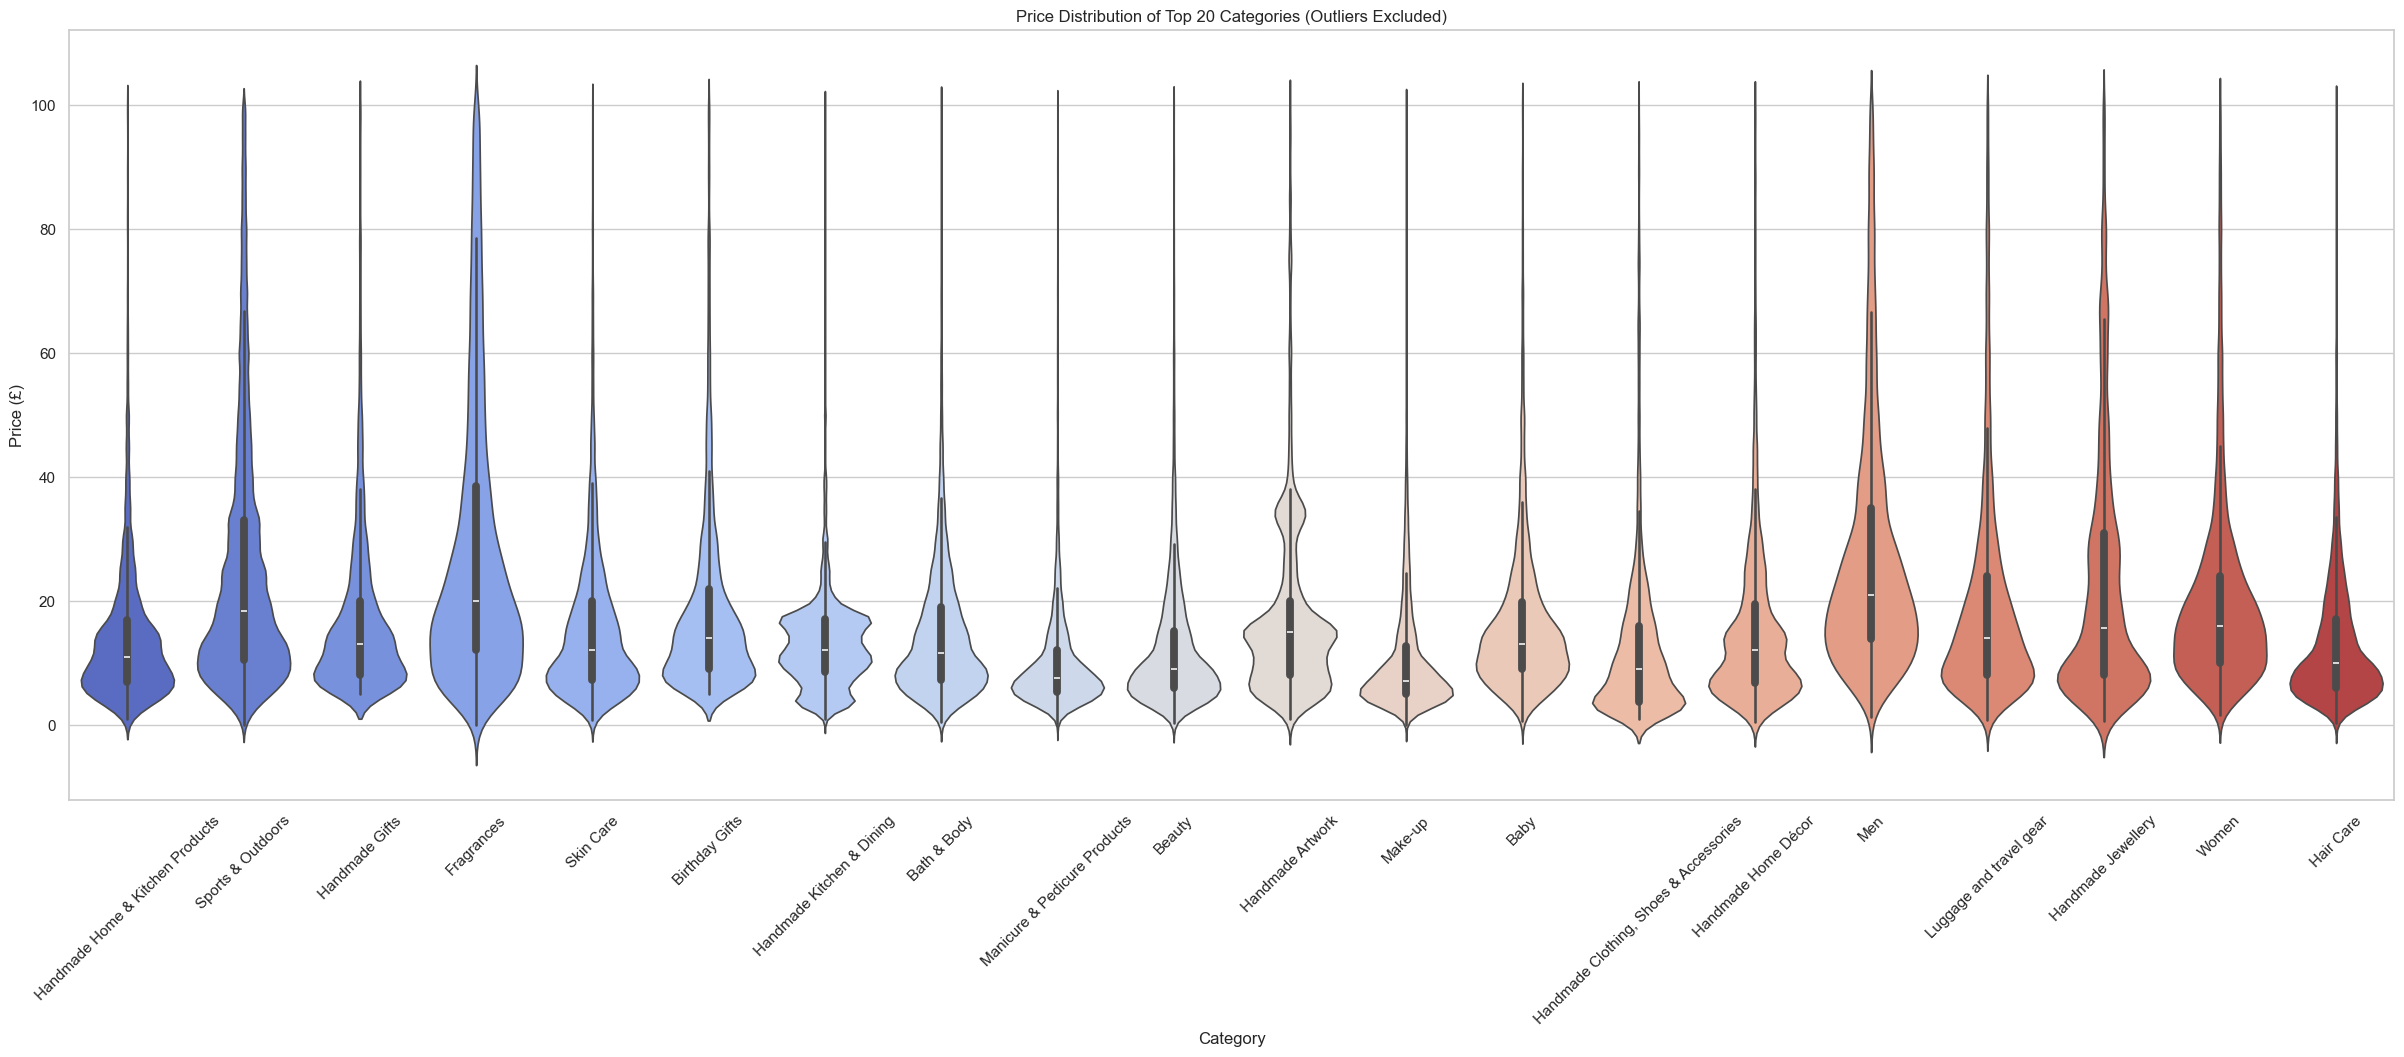

In [57]:
# violin plot of top 20 categories
top20 = df_clean['category'].value_counts().index[:20]
df_top20 = df_clean[df_clean['category'].isin(top20)]


# violinplot
sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=45)
plt.title("Price Distribution of Top 20 Categories (Outliers Excluded)")
plt.xlabel("Category")
plt.ylabel("Price (£)")
plt.show()

The violin plot shows us that the vast majority of prices are in the same range of 10 to 20 pounds across all categories. However, some categories display wider price ranges towards higher priices, with most of them thinning out pretty evenly.

#### 2.2 **Bar Charts**:
- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

C:\Users\black\AppData\Local\Temp\ipykernel_38004\3820118395.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10_mean, x="category", y="avg_price", palette="coolwarm")


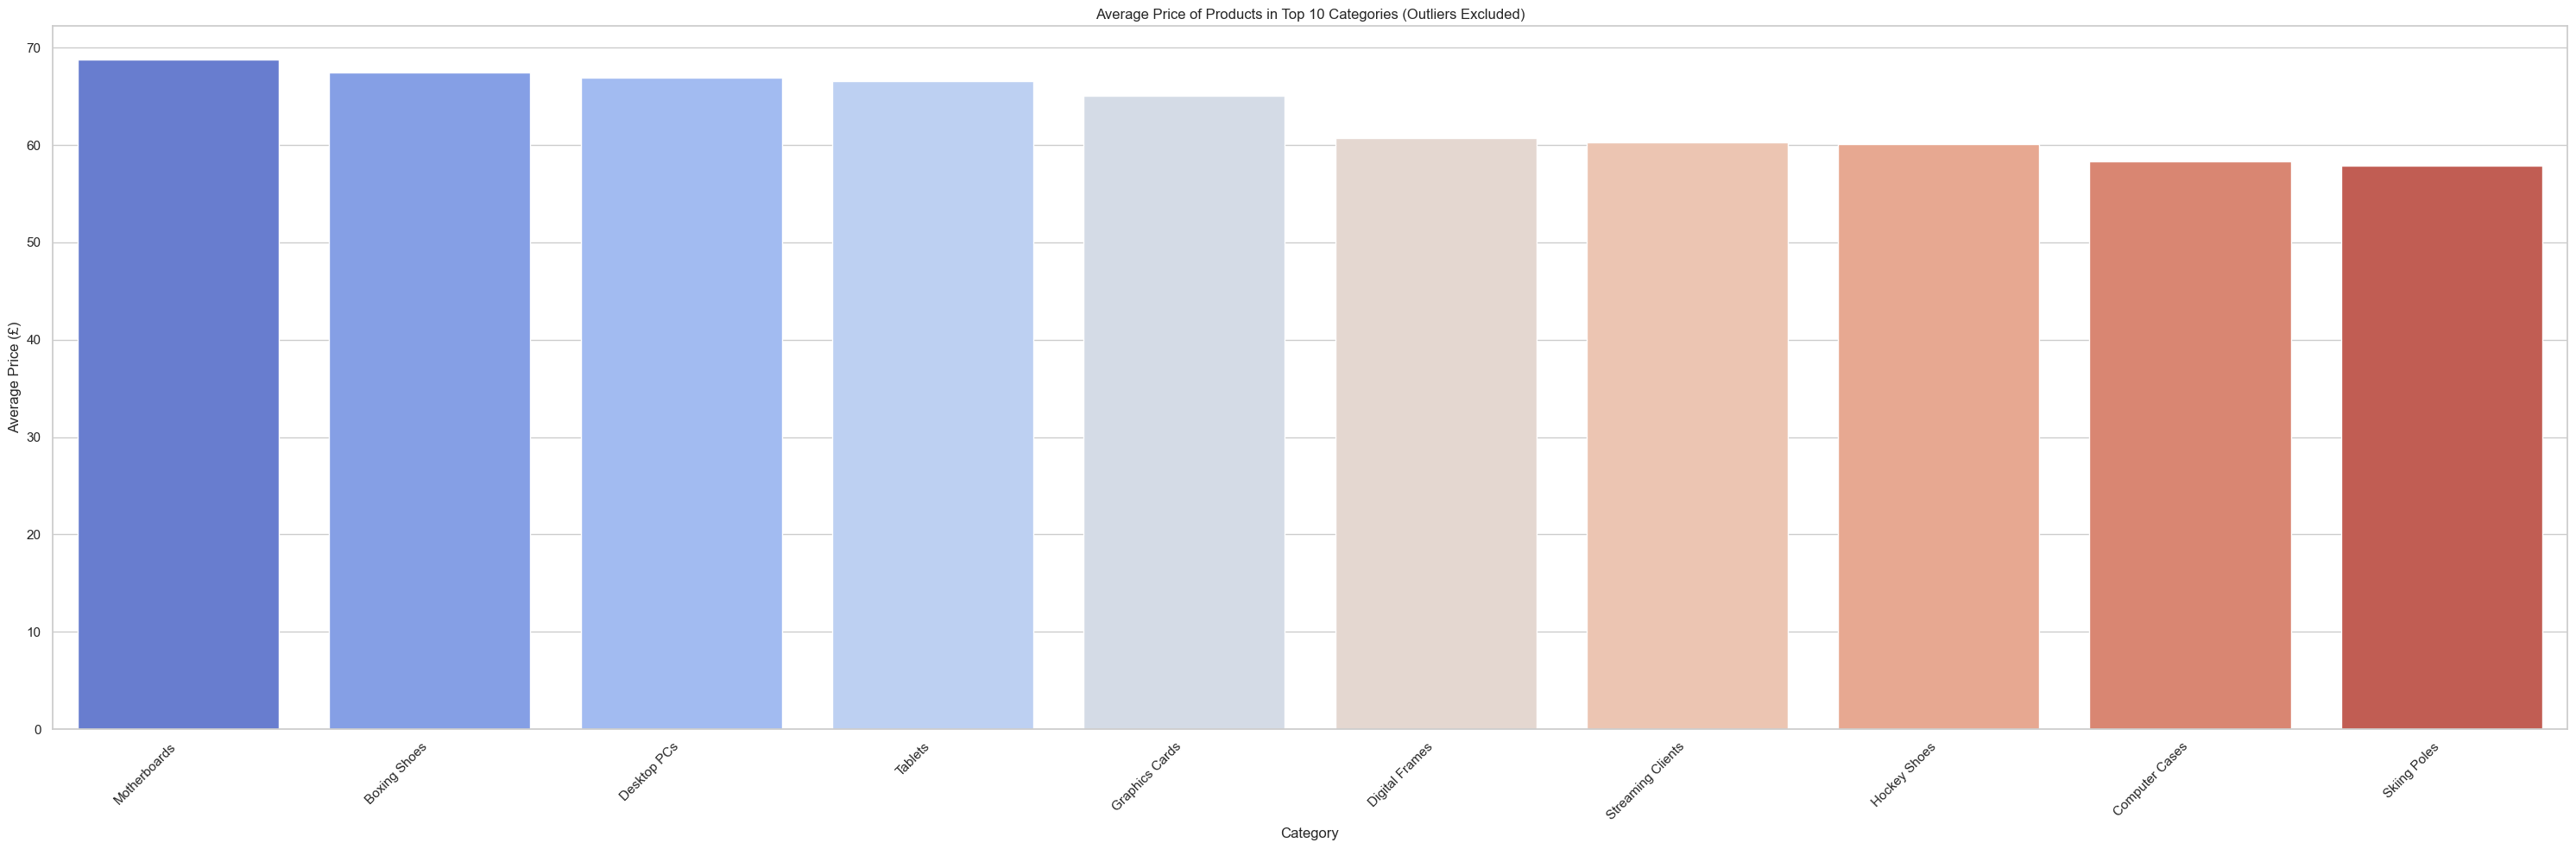

In [58]:
# filter top 10 mean prices + respective categories
cat_mean = df_clean.groupby('category')["price"].mean()
top10_mean = cat_mean.sort_values(ascending=False).head(10)
df_top10_mean = top10_mean.reset_index()
df_top10_mean.columns = ['category', 'avg_price']

# bar chart of top 10 categories
sns.barplot(data=df_top10_mean, x="category", y="avg_price", palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.title("Average Price of Products in Top 10 Categories (Outliers Excluded)")
plt.xlabel("Category")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.show()


The average price of the top 10 categories is very similar, starting at 68 pounds and going down to 58 pounds; so only a 10 pounds variation and almost going down in a pretty steady slope of ~2 pounds difference per category.

C:\Users\black\AppData\Local\Temp\ipykernel_38004\3569556176.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_mean, x="category", y="avg_price", palette="coolwarm")


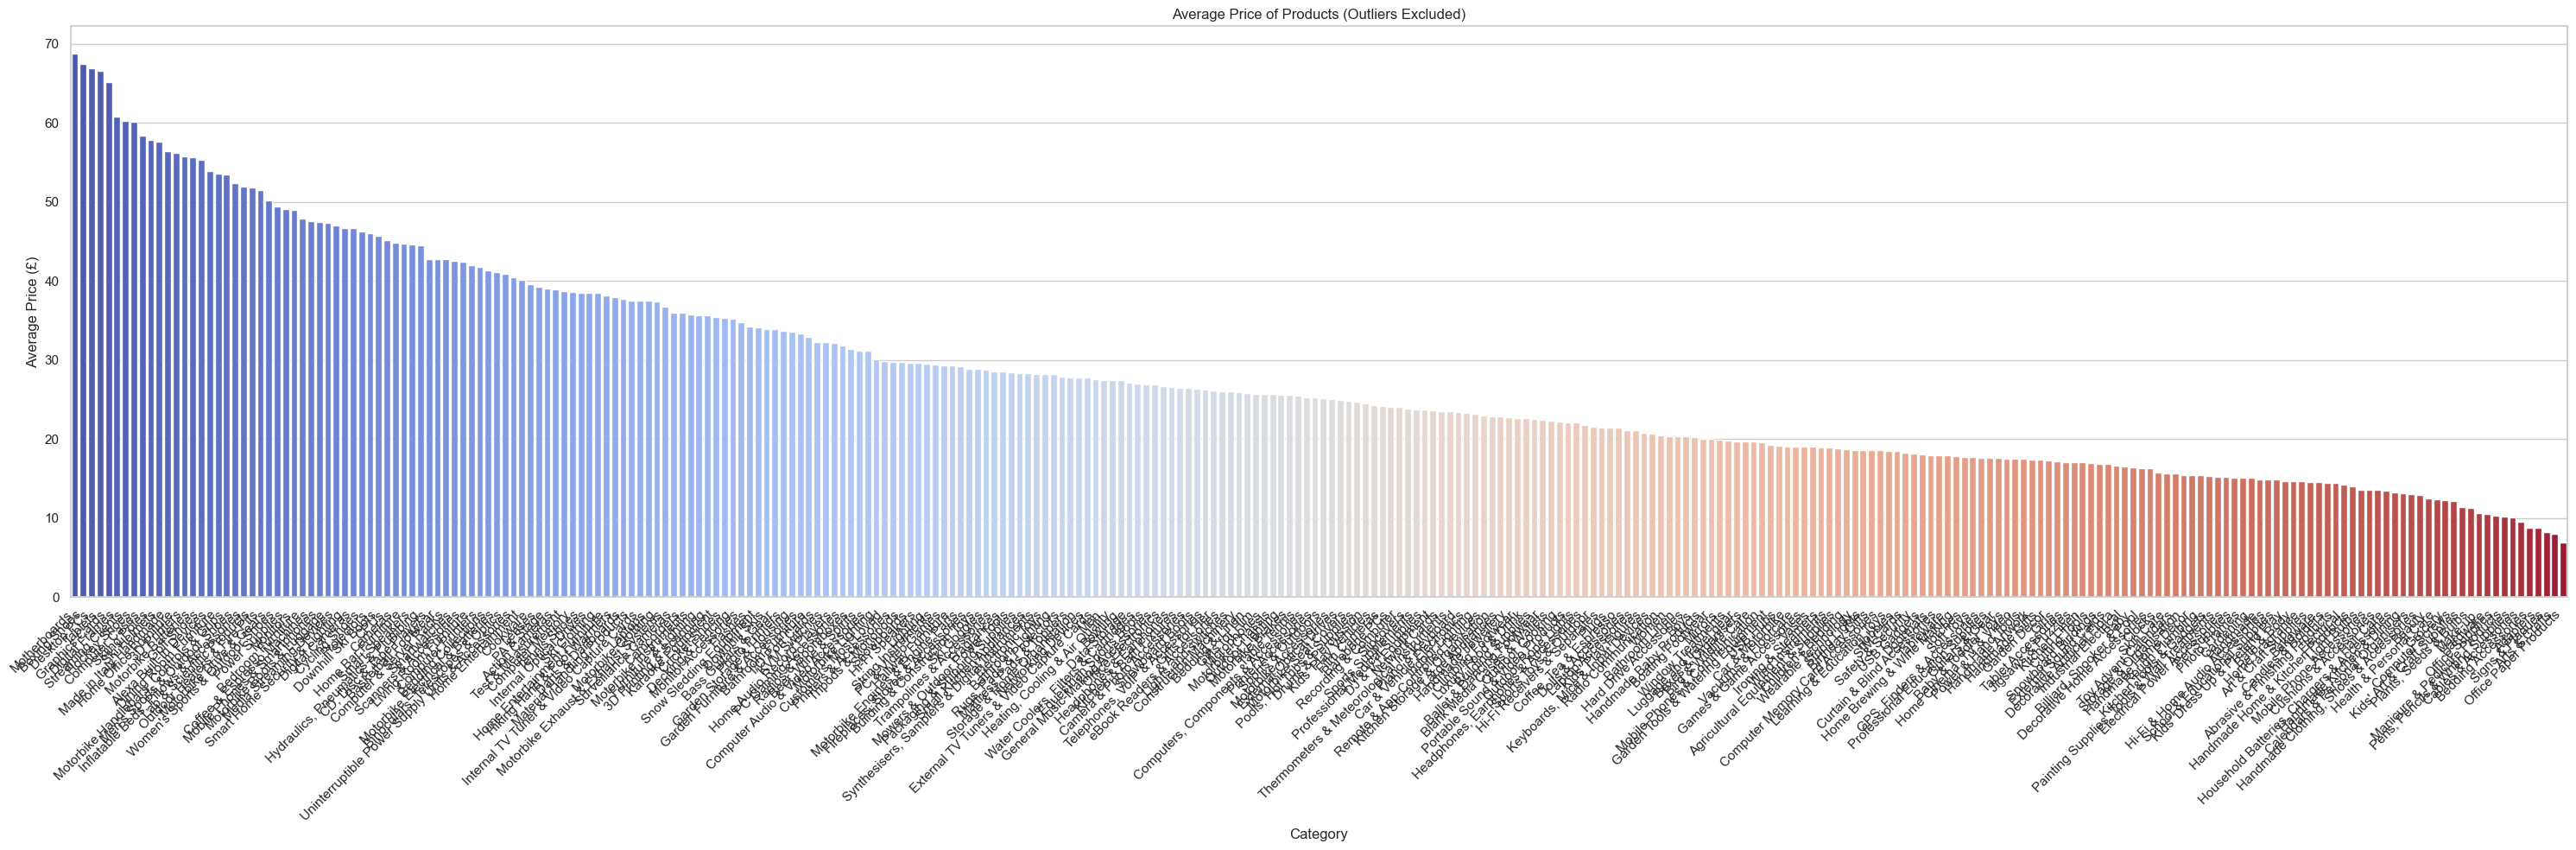

In [ ]:
# mean prices
cat_mean = df_clean.groupby('category')["price"].mean().sort_values(ascending=False)
df_mean = cat_mean.reset_index()
df_mean.columns = ['category', 'avg_price']

# bar chart mean price categories
sns.barplot(data=df_mean, x="category", y="avg_price", palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.title("Average Price of Products (Outliers Excluded)")
plt.xlabel("Category")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.show()

The price average across all categories behaves almost in a linear slope, ranging from 78 pounds at the top to 8 pounds at the bottom. The category "Motherboards" represents the category with the highest average price.

#### 2.3 **Box Plots**:
- Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

C:\Users\black\AppData\Local\Temp\ipykernel_38004\4133376086.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10_rate, x="category", y="stars", palette="coolwarm", legend=True)


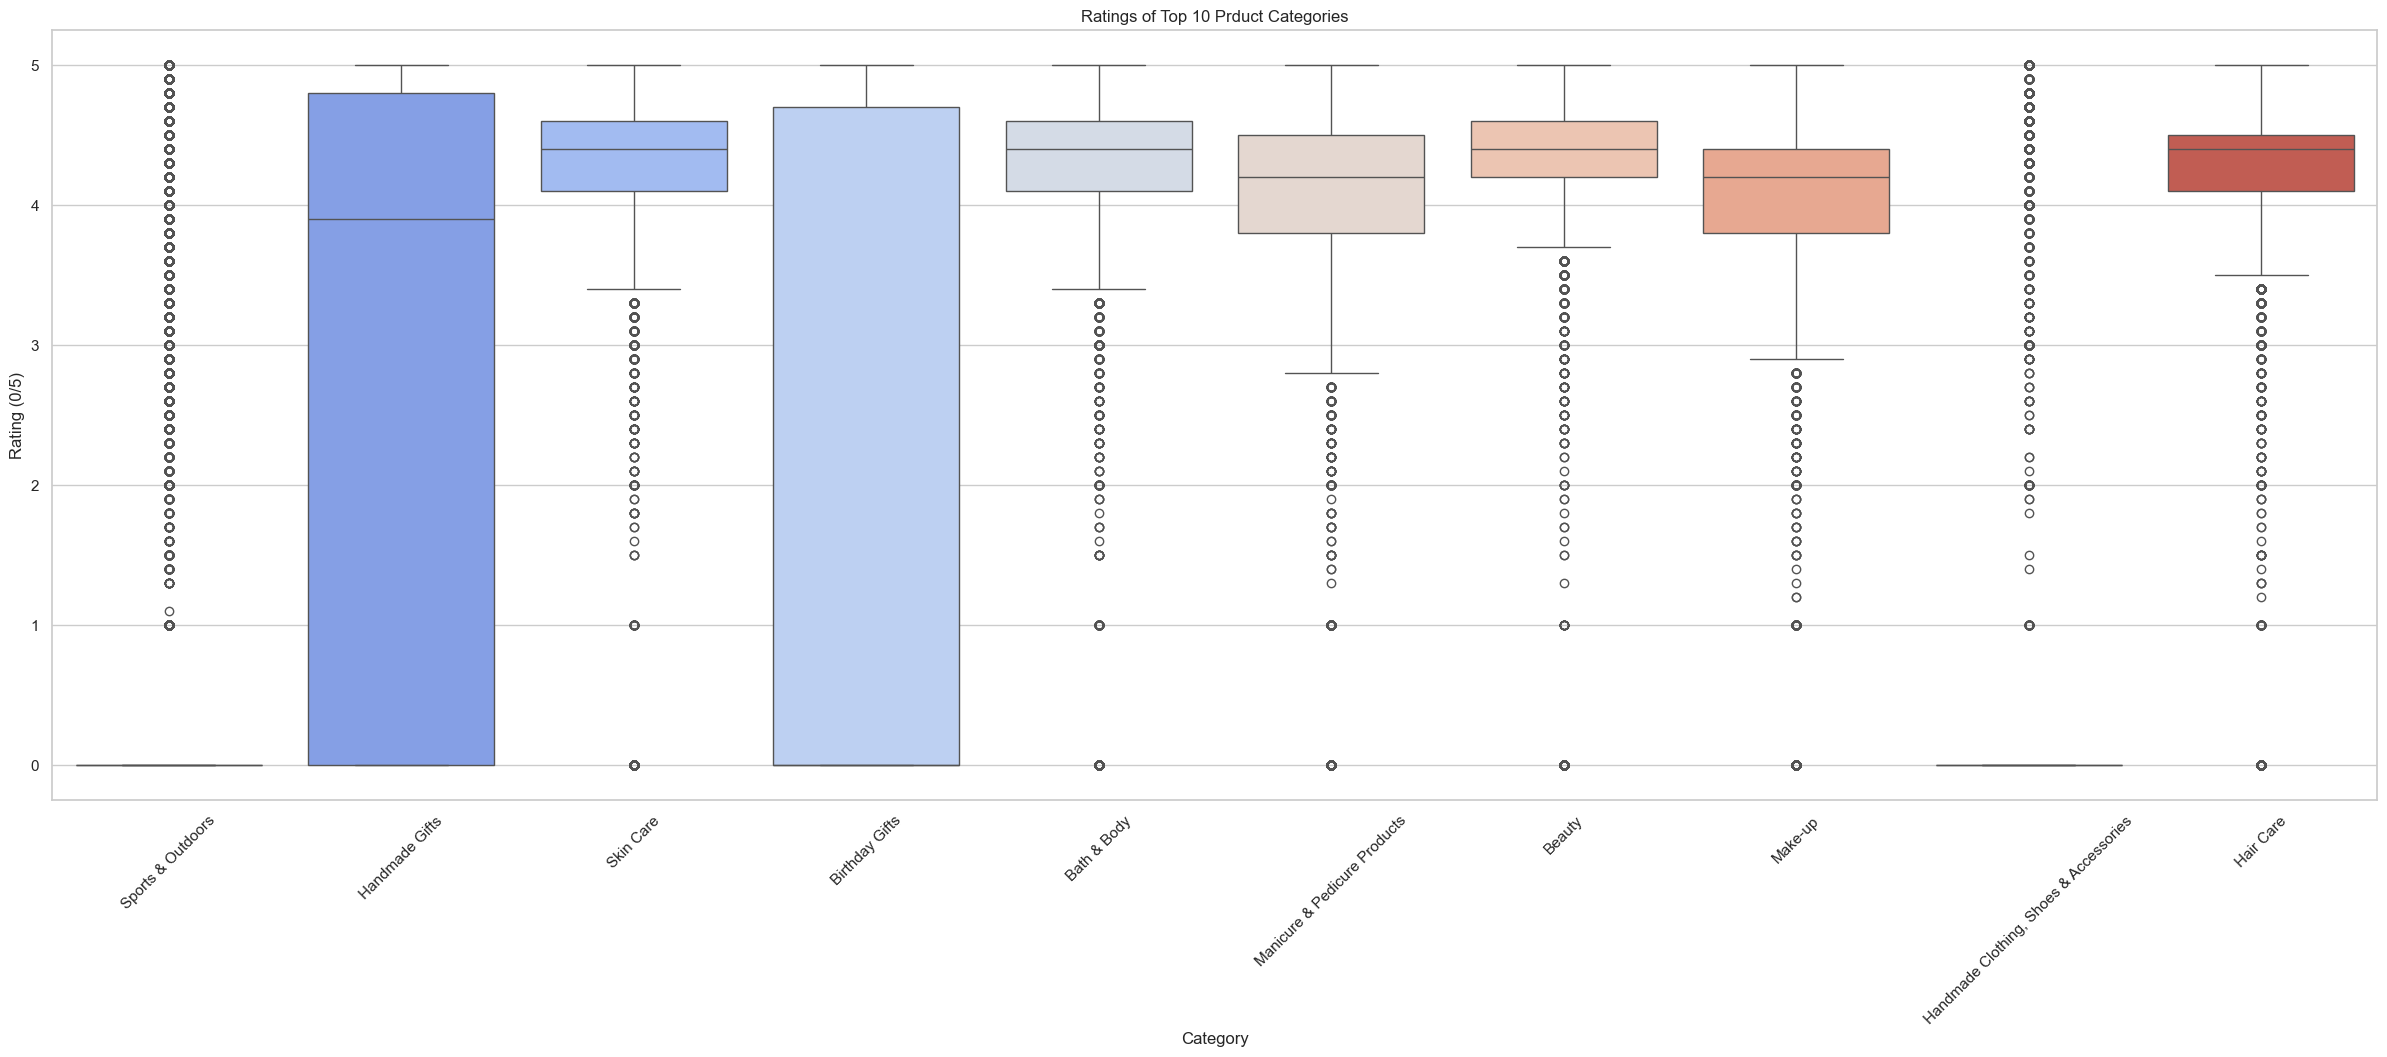

In [59]:
# filter top 10 protuct ratings + respective categories
top10 = df_clean['category'].value_counts().index[:10]
df_top10_rate = df_clean[df_clean['category'].isin(top10)]

# boxplot
sns.boxplot(data=df_top10_rate, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation=45)
plt.title("Ratings of Top 10 Prduct Categories")
plt.xlabel("Category")
plt.ylabel("Rating (0/5)")
plt.show()



As shown in yesterday's assignment, 0 stars are usually non-reviewed items. So let's see the data, but in a more clean version, where non-reviewed items are excluded. 

C:\Users\black\AppData\Local\Temp\ipykernel_38004\2537138139.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10_rev, x="category", y="stars", palette="coolwarm", legend=True)


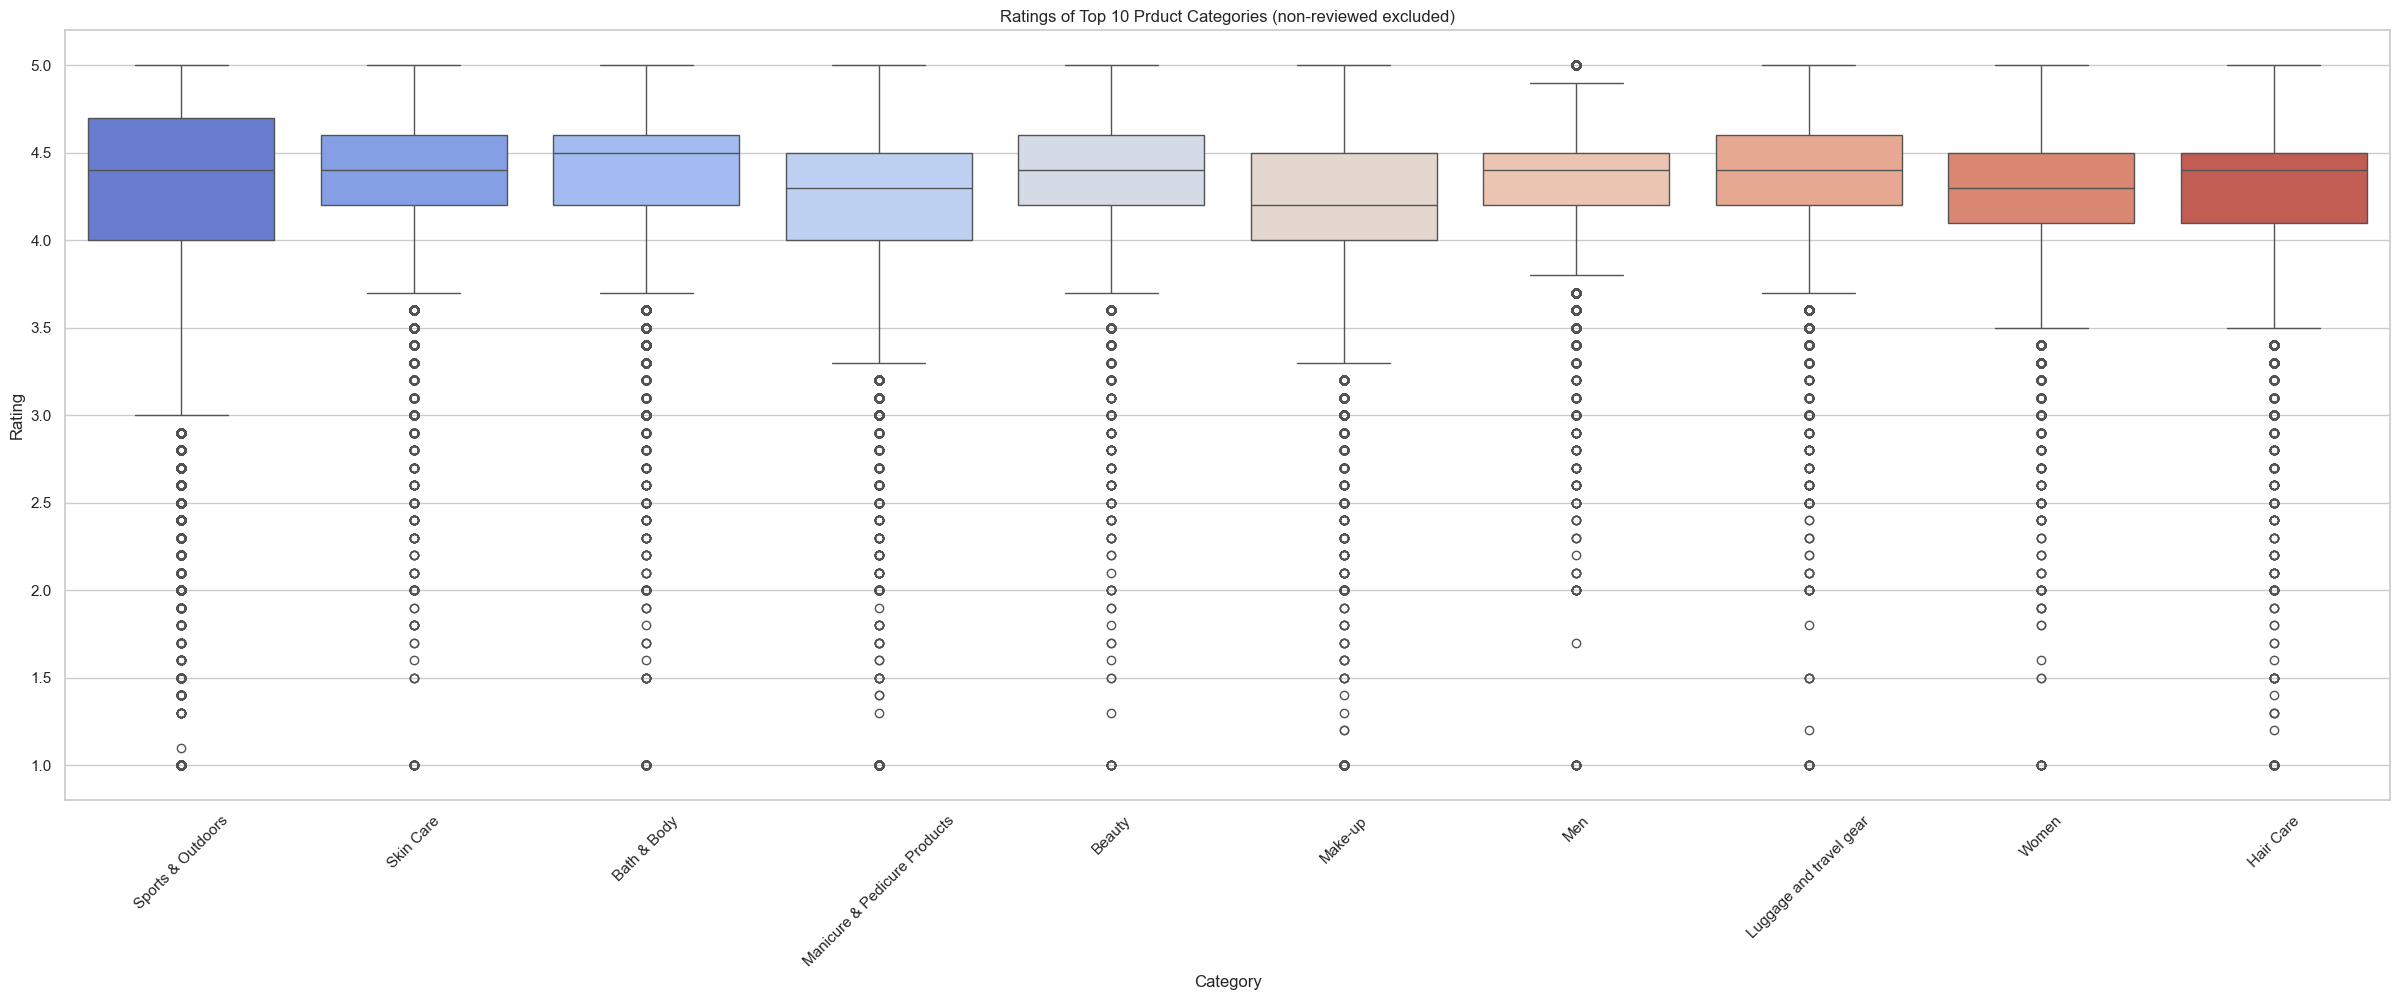

In [60]:
# filter out non-reviewed items
df_rev = df_clean[df_clean["reviews"] != 0]

# top 10 categories
top10_rev = df_rev["category"].value_counts().index[:10]
df_top10_rev = df_rev[df_rev["category"].isin(top10_rev)]

# boxplot
sns.boxplot(data=df_top10_rev, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation=45)
plt.title("Ratings of Top 10 Prduct Categories (non-reviewed excluded)")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.show()





The top 10 categories display a pretty similar mean rating of around 4.3 stars and none of them displays a max star rating above 4.7 or min rating under 4.0

Let's check the same thing across all categories.


C:\Users\black\AppData\Local\Temp\ipykernel_38004\3454371073.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rev, x="category", y="stars", palette="coolwarm", legend=True)


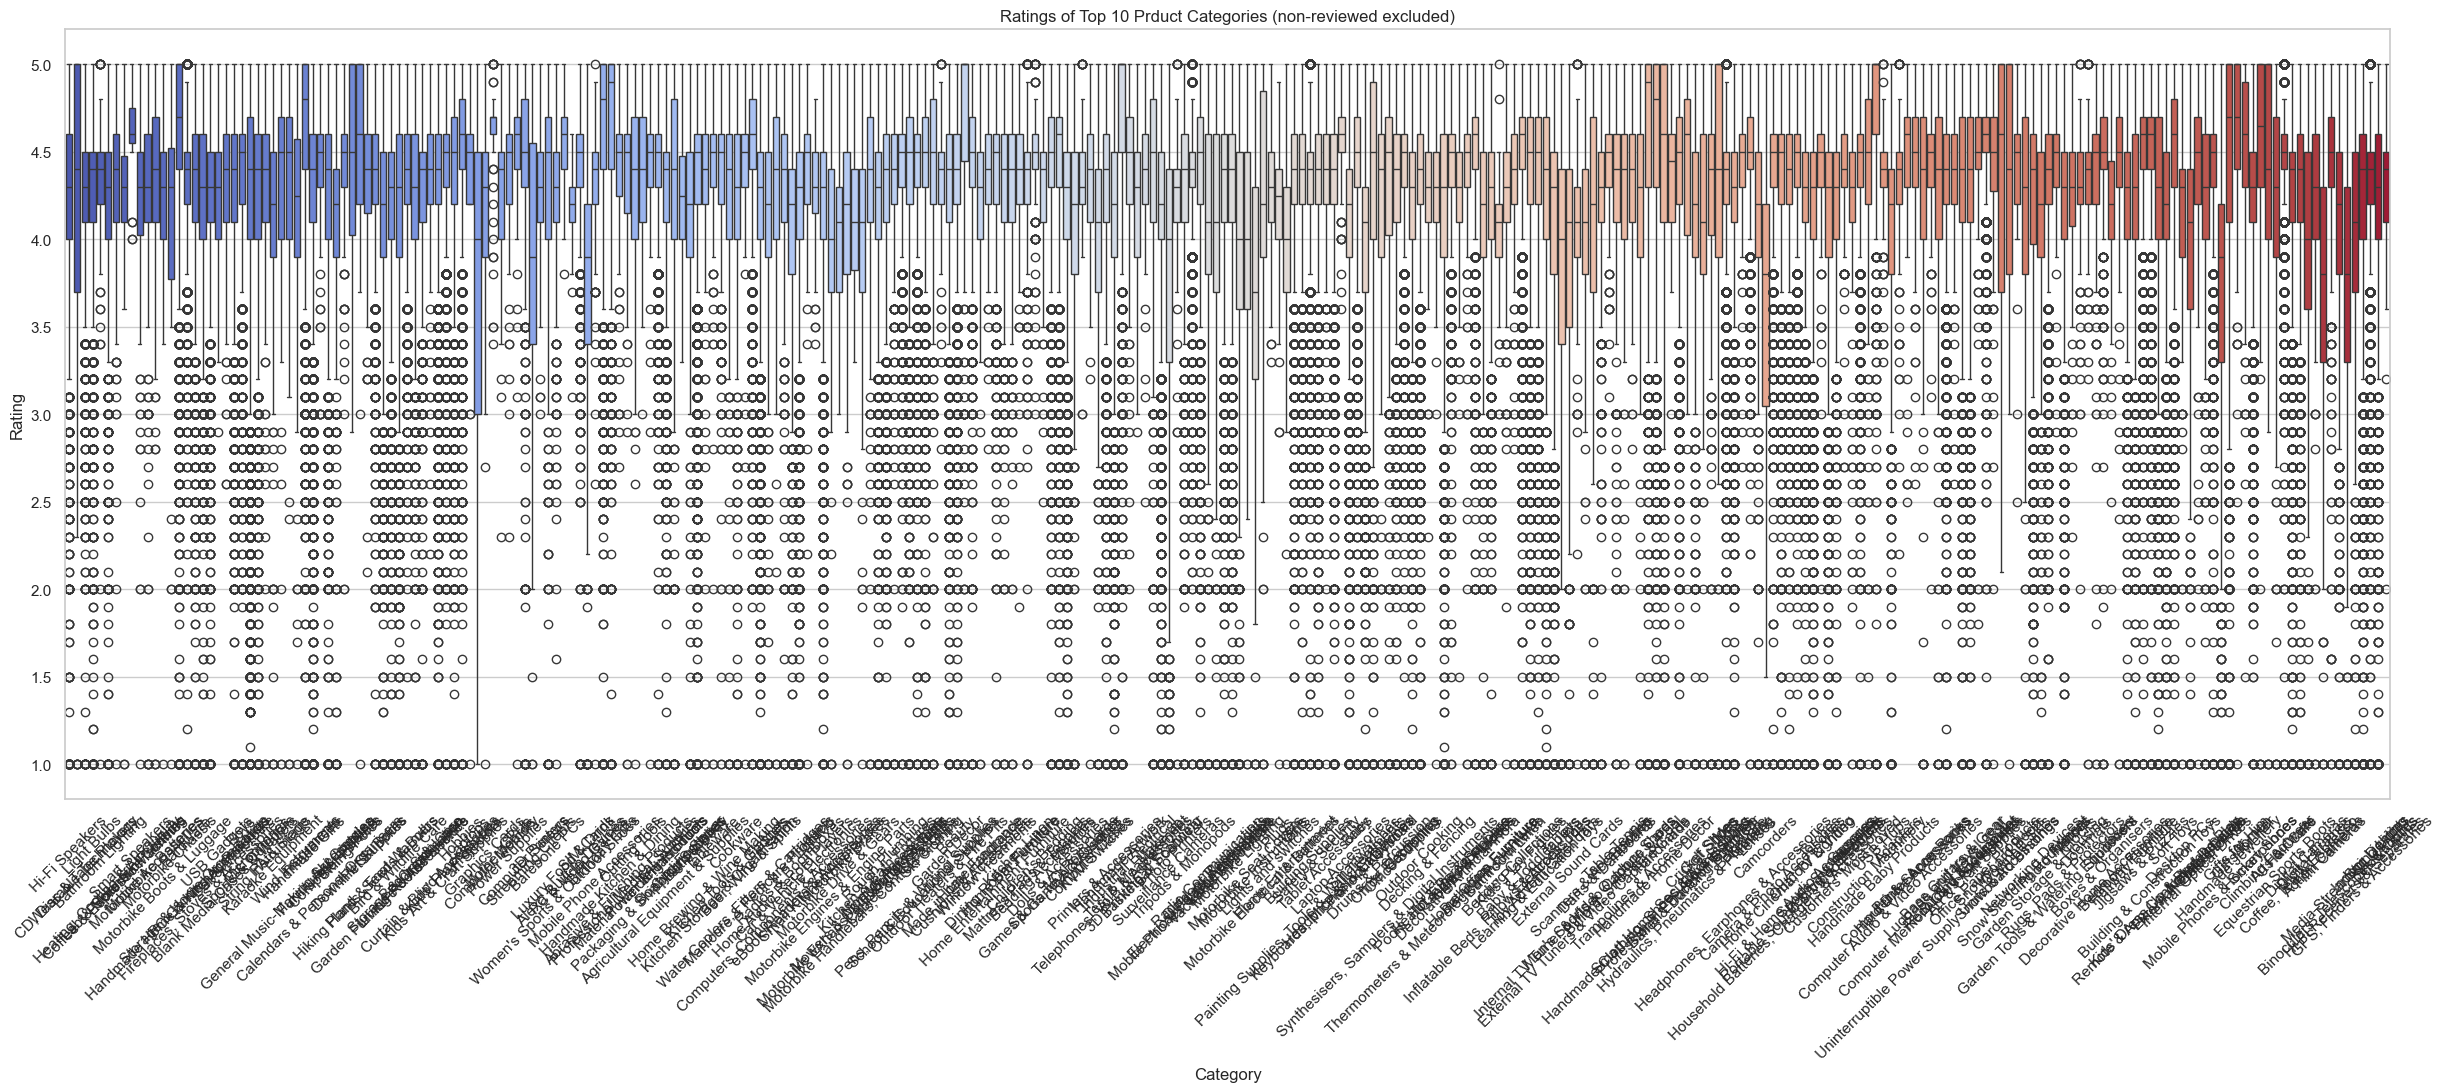

In [ ]:
# filter out non-reviewed items
df_rev = df_clean[df_clean["reviews"] != 0]

# boxplot
sns.boxplot(data=df_rev, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation=45)
plt.title("Ratings of Top 10 Prduct Categories (non-reviewed excluded)")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.show()



Across all categories we can see a higher variance of their respective ratings. However, non of them are displaying a rating minimum under 3.0 stars. We can see that across all categories, the standard rating is good (> 3 stars) and for the vast majority even very good (> 4.0 stars).

## Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.


### 3.1 **Correlation Coefficients**:
- Calculate the correlation coefficient between `price` and `stars`.
- Is there a significant correlation between product price and its rating?

In [50]:
# Calculating the Pearson correlation coefficient
round(float(df_rev["price"].corr(df_rev["stars"], method="pearson")), 5)

0.00674

In [51]:
# Calculating the Spearman rank correlation
round(float(df_rev["price"].corr(df_rev["stars"], method="spearman")), 5)


0.02466

The correlation factors are both indicating little to no linear/monotonic correlation between the product prices and their respective ratings, as both, the spearman and pearson value, are close to 0.

### 3.2 **Visualizations**:
- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.

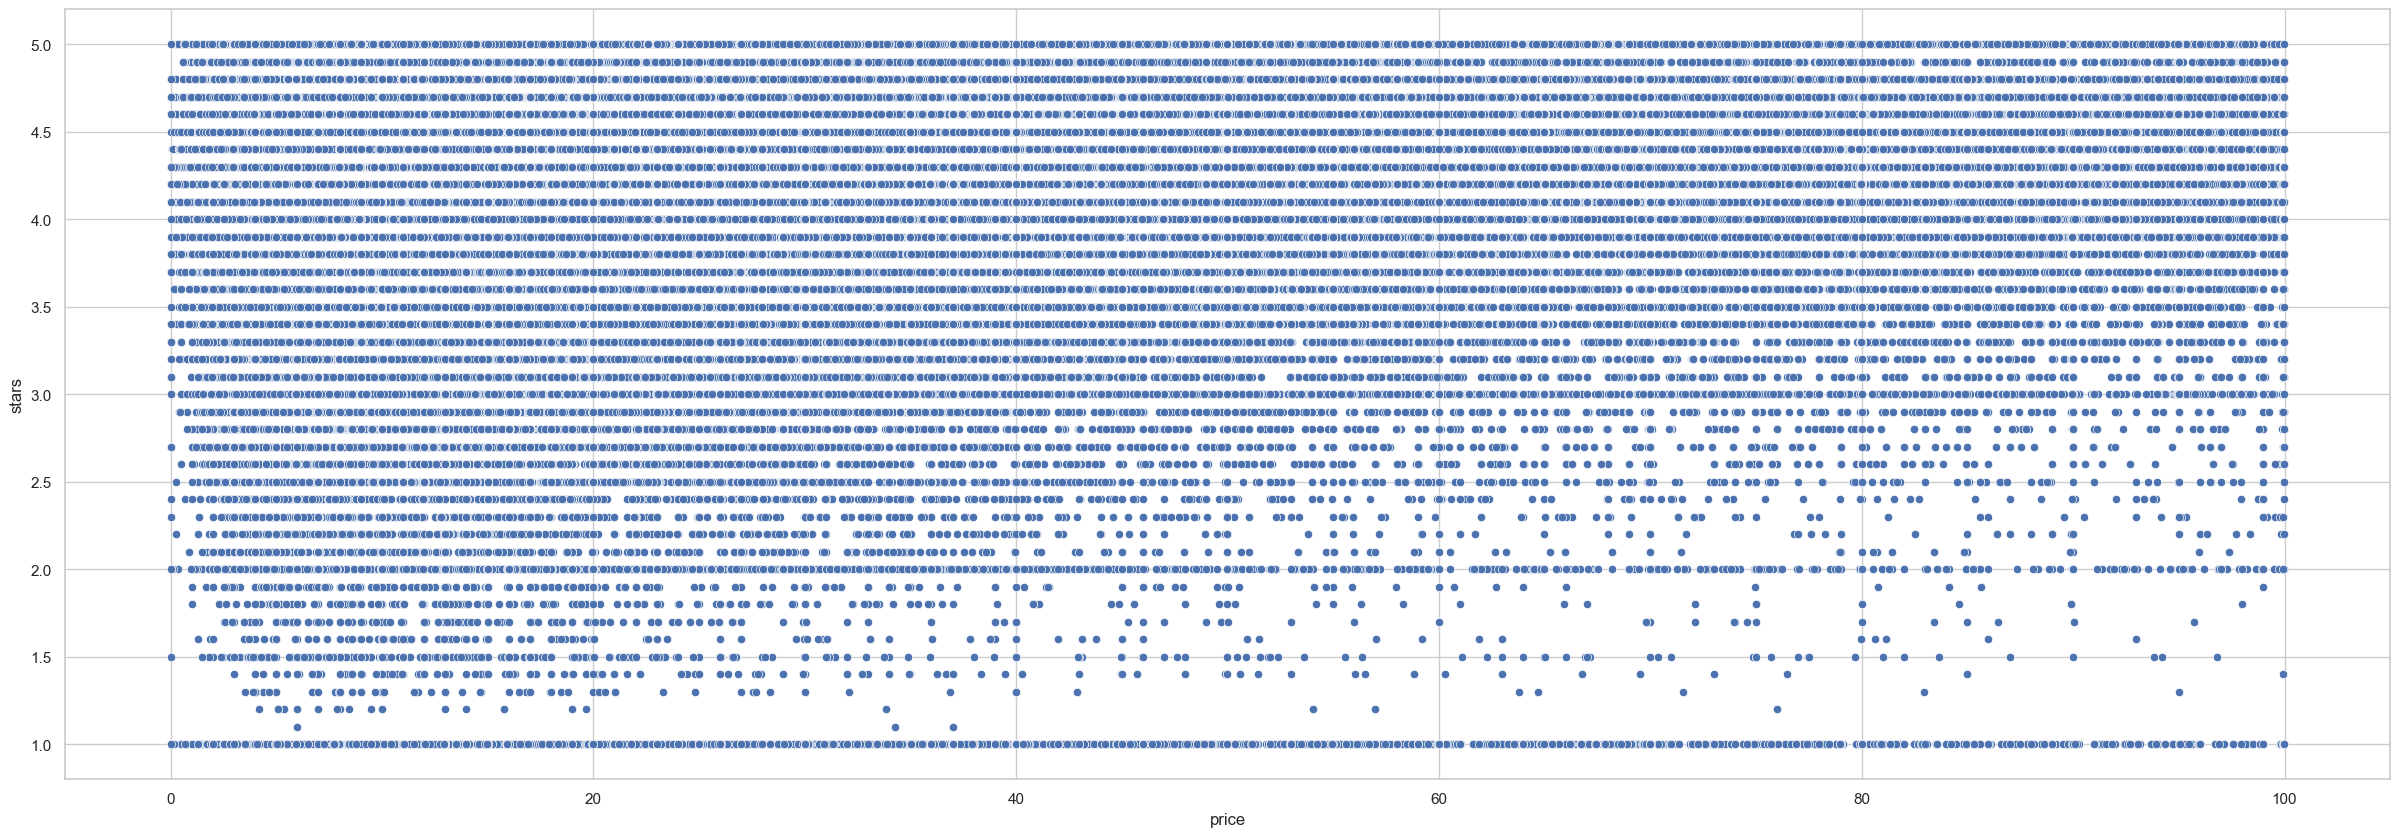

In [61]:
# Plotting a scatter plot to visualize the relationship 
sns.scatterplot(data=df_rev, x='price', y='stars')
plt.show()

The scatter plot between is supporting what the correlation coefficients displayed: very low to no correlation between the price and the rating of items. We can see that the data is almost evenly distributed across the whole range.